In [5]:
pip install mysql-connector-python sqlalchemy pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
print("Ready")

Ready


Step-1: Load the Pandas library and read the spreadsheet

In [ ]:
import pandas as pd

In [10]:
df = pd.read_csv('~/Downloads/ai4i2020.csv')

In [16]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Step-2: Check Data Health(Rows,Missing Values,Duplicates)

In [20]:
# Check total rows and columns
print("Rows and Columns:", df.shape)

# Check for missing values
print("\nMissing Values:\n", df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Rows and Columns: (10000, 14)

Missing Values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Rows: 0


Step-3: Calculate Overall Failure

In [26]:
total_runs = len(df)
total_failures = df['Machine failure'].sum()
failure_rate = round((total_failures / total_runs) * 100, 2)

print(f"Total Production Runs: {total_runs}")
print(f"Total Machine Failures: {total_failures}")
print(f"Overall Failure Rate: {failure_rate}%")


Total Production Runs: 10000
Total Machine Failures: 339
Overall Failure Rate: 3.39%


Step-4: Find Machine type breaks down most

In [28]:
type_summary = df.groupby('Type')['Machine failure'].agg(
    Total_Runs='count',
    Failed_Runs='sum',
    Failure_Rate_Pct=lambda x: round(x.mean() * 100, 2)
).reset_index()

print(type_summary)


  Type  Total_Runs  Failed_Runs  Failure_Rate_Pct
0    H        1003           21              2.09
1    L        6000          235              3.92
2    M        2997           83              2.77


In [ ]:
Step-5: Identify the Top Root Cause of Failures

In [30]:
failure_counts = {
    'Heat Dissipation (HDF)': df['HDF'].sum(),
    'Overstrain (OSF)': df['OSF'].sum(),
    'Power Failure (PWF)': df['PWF'].sum(),
    'Tool Wear (TWF)': df['TWF'].sum(),
    'Random Failure (RNF)': df['RNF'].sum()
}

causes_df = pd.DataFrame(list(failure_counts.items()), columns=['Failure_Cause', 'Count'])
causes_df = causes_df.sort_values(by='Count', ascending=False)

print(causes_df)


            Failure_Cause  Count
0  Heat Dissipation (HDF)    115
1        Overstrain (OSF)     98
2     Power Failure (PWF)     95
3         Tool Wear (TWF)     46
4    Random Failure (RNF)     19


Step-6: Create and Save two charts

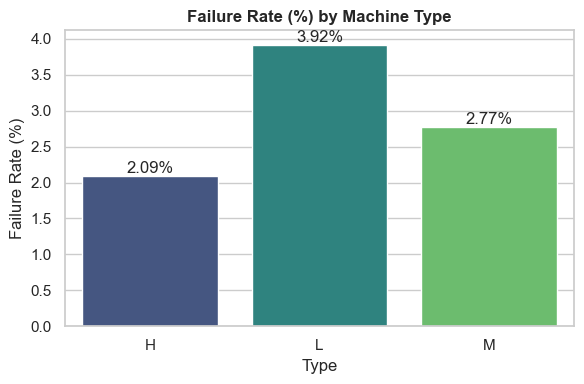

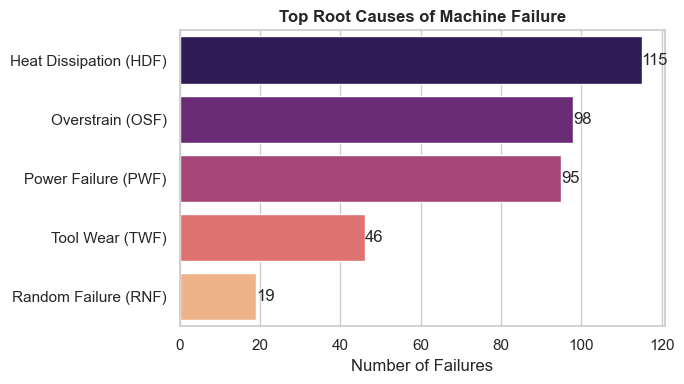

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Chart 1: Failure Rate by Machine Type
plt.figure(figsize=(6, 4))
ax1 = sns.barplot(data=type_summary, x='Type', y='Failure_Rate_Pct', hue='Type', palette='viridis', legend=False)
plt.title('Failure Rate (%) by Machine Type', fontweight='bold')
plt.ylabel('Failure Rate (%)')
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.2f%%')
plt.tight_layout()
plt.savefig('chart1_failure_by_type.png', dpi=300)
plt.show()

# Chart 2: Primary Causes of Machine Failure
plt.figure(figsize=(7, 4))
ax2 = sns.barplot(data=causes_df, x='Count', y='Failure_Cause', hue='Failure_Cause', palette='magma', legend=False)
plt.title('Top Root Causes of Machine Failure', fontweight='bold')
plt.xlabel('Number of Failures')
plt.ylabel('')
for container in ax2.containers:
    ax2.bar_label(container)
plt.tight_layout()
plt.savefig('chart2_root_causes.png', dpi=300)
plt.show()
